# Setup
## Dependencies

In [16]:
%config InlineBackend.figure_format = 'retina'
from pathlib import Path
import sqlite3
from astropy.io import fits
from astropy.time import Time
from astropy.coordinates import SkyCoord
from snpy import get_sn

## File Paths

In [17]:
db_path = Path("../databases/Master_Database.db").resolve()
conn = sqlite3.connect(db_path)

mosaic_folder = Path("../output mosaics/flats")
output_folder = Path("../output snoopy")

max_mag_err = 2

## Dictionaries

In [18]:
snoopy_targets = {
    "SN2026AAIV": 0.002722,
    "SN2026ACNA": 0.017365,
    "SN2026AEIV": 0.0078,
}

In [19]:
sn_coordinates = {
    "aaiv": ("22h37m05.618s", "+34d24m35.37s"),
    "acna": ("01h48m51.954s", "+10d35m11.40s"),
    "aeiv": ("03h16m41.828s", "+80d48m09.12s"),
}

In [20]:
snoopy_filters = {
    "B": "Bs",
    "V": "Vs",
    "R": "Rs",
    "I": "Is",
}

# Functions

In [21]:
def get_target_data(conn, object_name):
    sql = """
        SELECT filter, mosaic_name_f, mag_f, mag_err_f
        FROM observations
        WHERE object = ?
            AND mag_f IS NOT NULL
        ORDER BY obs_date
    """
    
    output = conn.execute(sql, (object_name,)).fetchall()
    return output

In [22]:
def convert_mjd(mosaic_path):
    header = fits.getheader(mosaic_path)
    start_time = Time(header["DATE-OBS"], format="isot", scale="utc")
    return start_time.mjd

In [23]:
def write_snoopy_file(conn, object_name, redshift, output_folder):
    rows = get_target_data(conn, object_name)

    short_sn_name = object_name[-4:].lower()
    ra_text, dec_text = sn_coordinates[short_sn_name]
    position = SkyCoord(ra_text, dec_text)
    ra_deg = position.ra.deg
    dec_deg = position.dec.deg


    snoopy_name = object_name[:6] + object_name[6:].lower()

    points = {"Bs": [], "Vs": [], "Rs": [], "Is": []}
    skipped_band = 0
    skipped_error = 0

    for band, mosaic_name, mag, mag_err in rows:
        if band not in snoopy_filters:
            skipped_band = skipped_band + 1
            continue

        if mag_err is None or mag_err > max_mag_err:
            skipped_error = skipped_error + 1
            continue

        mjd = convert_mjd(mosaic_folder / mosaic_name)
        filter_name = snoopy_filters[band]
        points[filter_name].append((mjd, mag, mag_err))

    lines = [f"{snoopy_name} {redshift} {ra_deg:.6f} {dec_deg:.6f}"]

    for filter_name in points:
        filter_points = sorted(points[filter_name])
        if len(filter_points) == 0:
            continue

        lines.append(f"filter {filter_name}")
        for mjd, mag, mag_err in filter_points:
            lines.append(f"{mjd:.5f}  {mag:.3f}  {mag_err:.3f}")

    output_folder.mkdir(parents=True, exist_ok=True)
    output_file = output_folder / f"{snoopy_name}_snoopy.txt"
    output_file.write_text("\n".join(lines) + "\n")

    print(snoopy_name, "->", output_file.name)
    for filter_name in points:
        print("   ", filter_name, len(points[filter_name]), "points")
    print("    skipped (r or C band):", skipped_band)
    print("    skipped (error too big):", skipped_error)

    return output_file

# Export SNooPy Files

In [24]:
for object_name in snoopy_targets:
    redshift = snoopy_targets[object_name]
    write_snoopy_file(conn, object_name, redshift, output_folder)

SN2026aaiv -> SN2026aaiv_snoopy.txt
    Bs 13 points
    Vs 19 points
    Rs 13 points
    Is 12 points
    skipped (r or C band): 4
    skipped (error too big): 0
SN2026acna -> SN2026acna_snoopy.txt
    Bs 2 points
    Vs 10 points
    Rs 12 points
    Is 9 points
    skipped (r or C band): 2
    skipped (error too big): 0
SN2026aeiv -> SN2026aeiv_snoopy.txt
    Bs 4 points
    Vs 7 points
    Rs 4 points
    Is 4 points
    skipped (r or C band): 4
    skipped (error too big): 0


# SNooPy Fit
`get_sn` first tries to read the file as a saved SNooPy object, so it prints
"could not load pickle file ... trying as plain text import". That is normal.

--------------------------------------------------------------------------------
SN  SN2026aaiv
z = 0.0027          zcmb = 0.0016          ra=339.27341         dec= 34.40982 
Data in the following bands: Bs,  Vs,  Rs,  Is,  
Fit results (if any):
   DM = 30.761  +/-  0.022  +/- 0.087 (sys)
   st = 0.901  +/-  0.012  +/- 0.030 (sys)
   EBVhost = 0.168  +/-  0.020  +/- 0.060 (sys)
   Tmax = 61297.740  +/-  0.455  +/- 0.340 (sys)


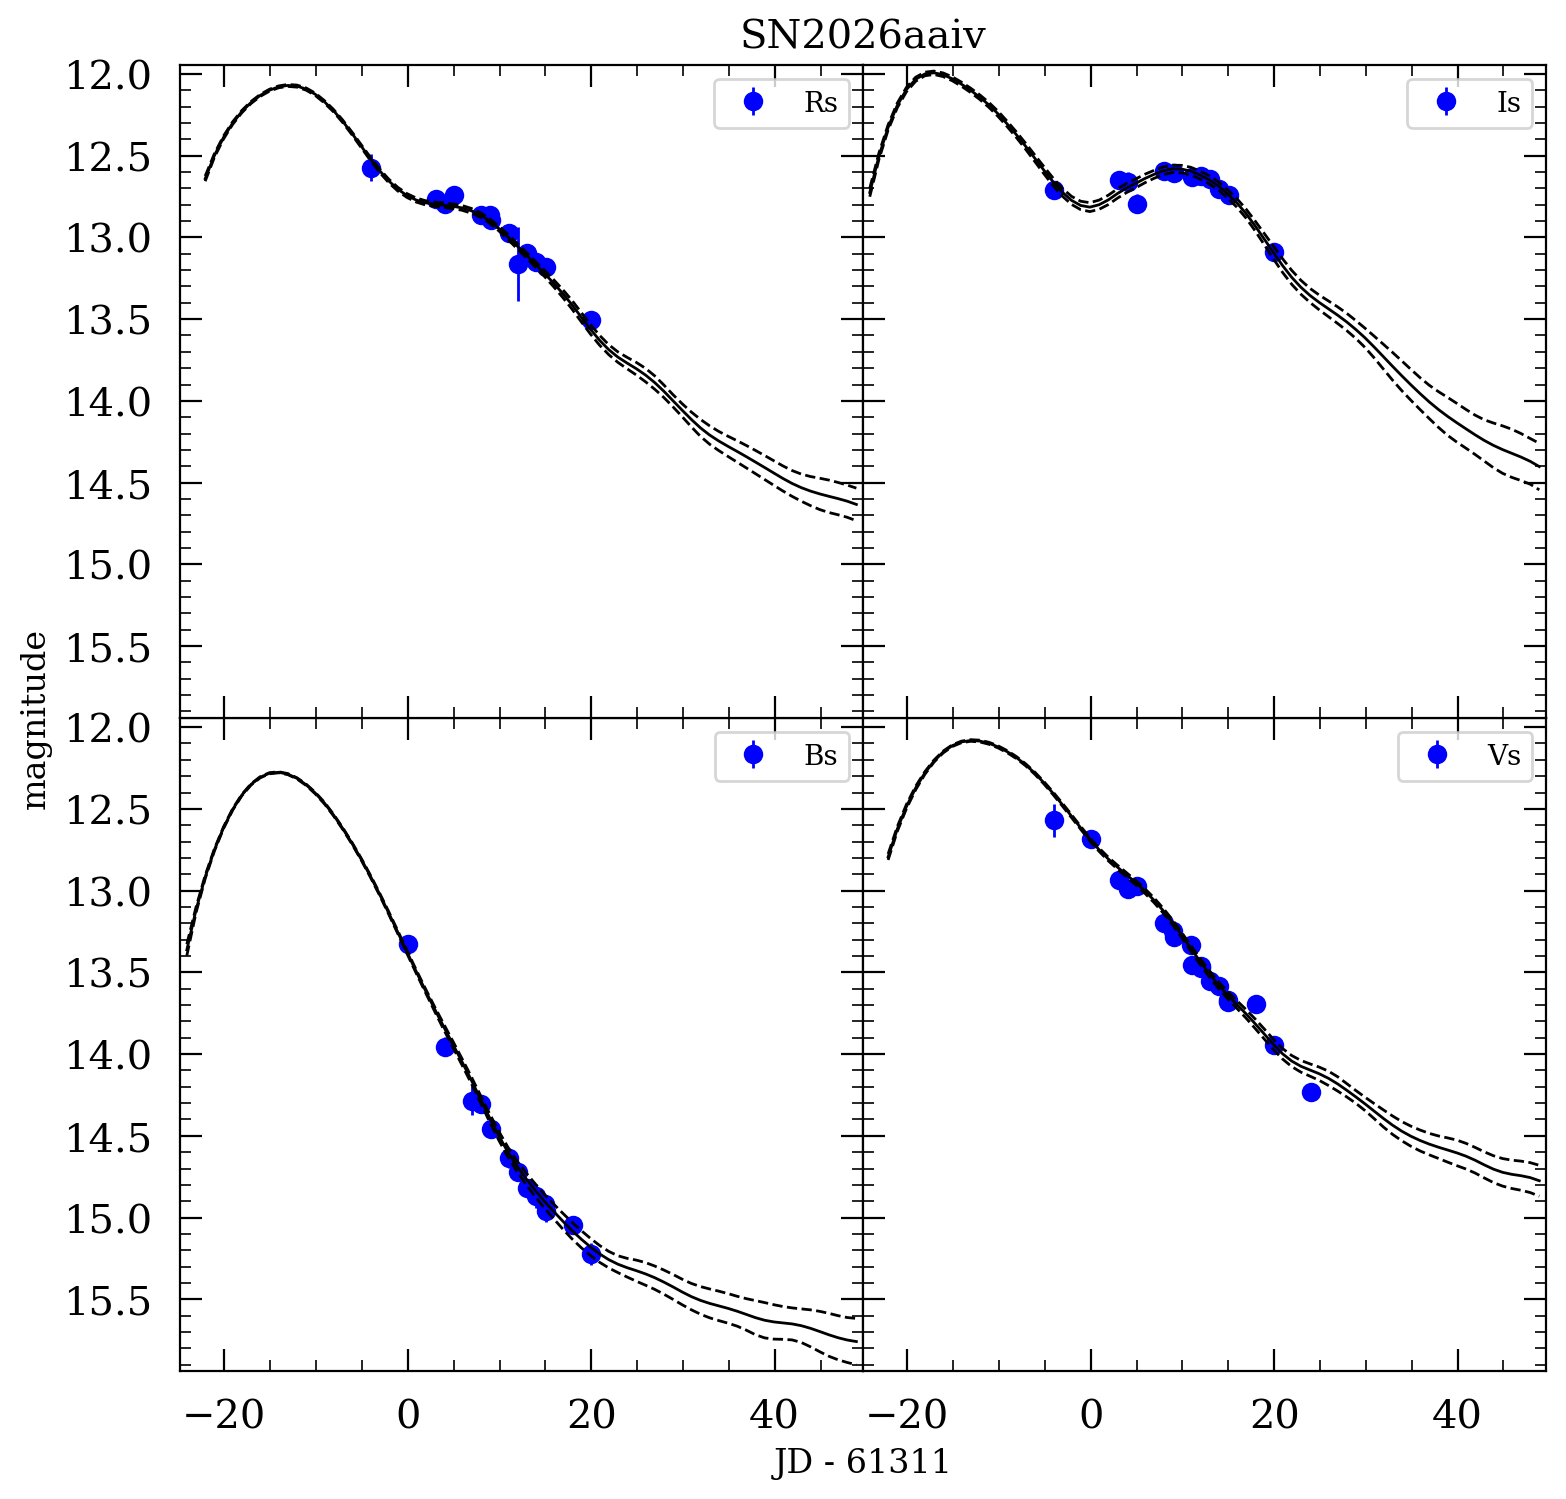

In [30]:
sn_file = output_folder / "SN2026aaiv_snoopy.txt"
sn_file = output_folder / "SN2026aaiv.snpy"

s = get_sn(str(sn_file))
s.choose_model("EBV_model2", stype="st")
s.fit()
s.summary()

s.plot(outfile=str(output_folder / f"{s.name}_fit.pdf"))

with (output_folder / f"{s.name}_summary.txt").open("w") as file:
    s.summary(out=file)


s.save(str(output_folder / f"{s.name}.snpy"))

--------------------------------------------------------------------------------
SN  SN2026acna
z = 0.0174          zcmb = 0.0164          ra= 27.21647         dec= 10.58650 
Data in the following bands: Bs,  Vs,  Rs,  Is,  
Fit results (if any):
   DM = 33.613  +/-  0.180  +/- 0.130 (sys)
   st = 1.707  +/-  0.352  +/- 0.030 (sys)
   EBVhost = 0.372  +/-  0.719  +/- 0.060 (sys)
   Tmax = 61311.570  +/-  10.631  +/- 0.340 (sys)


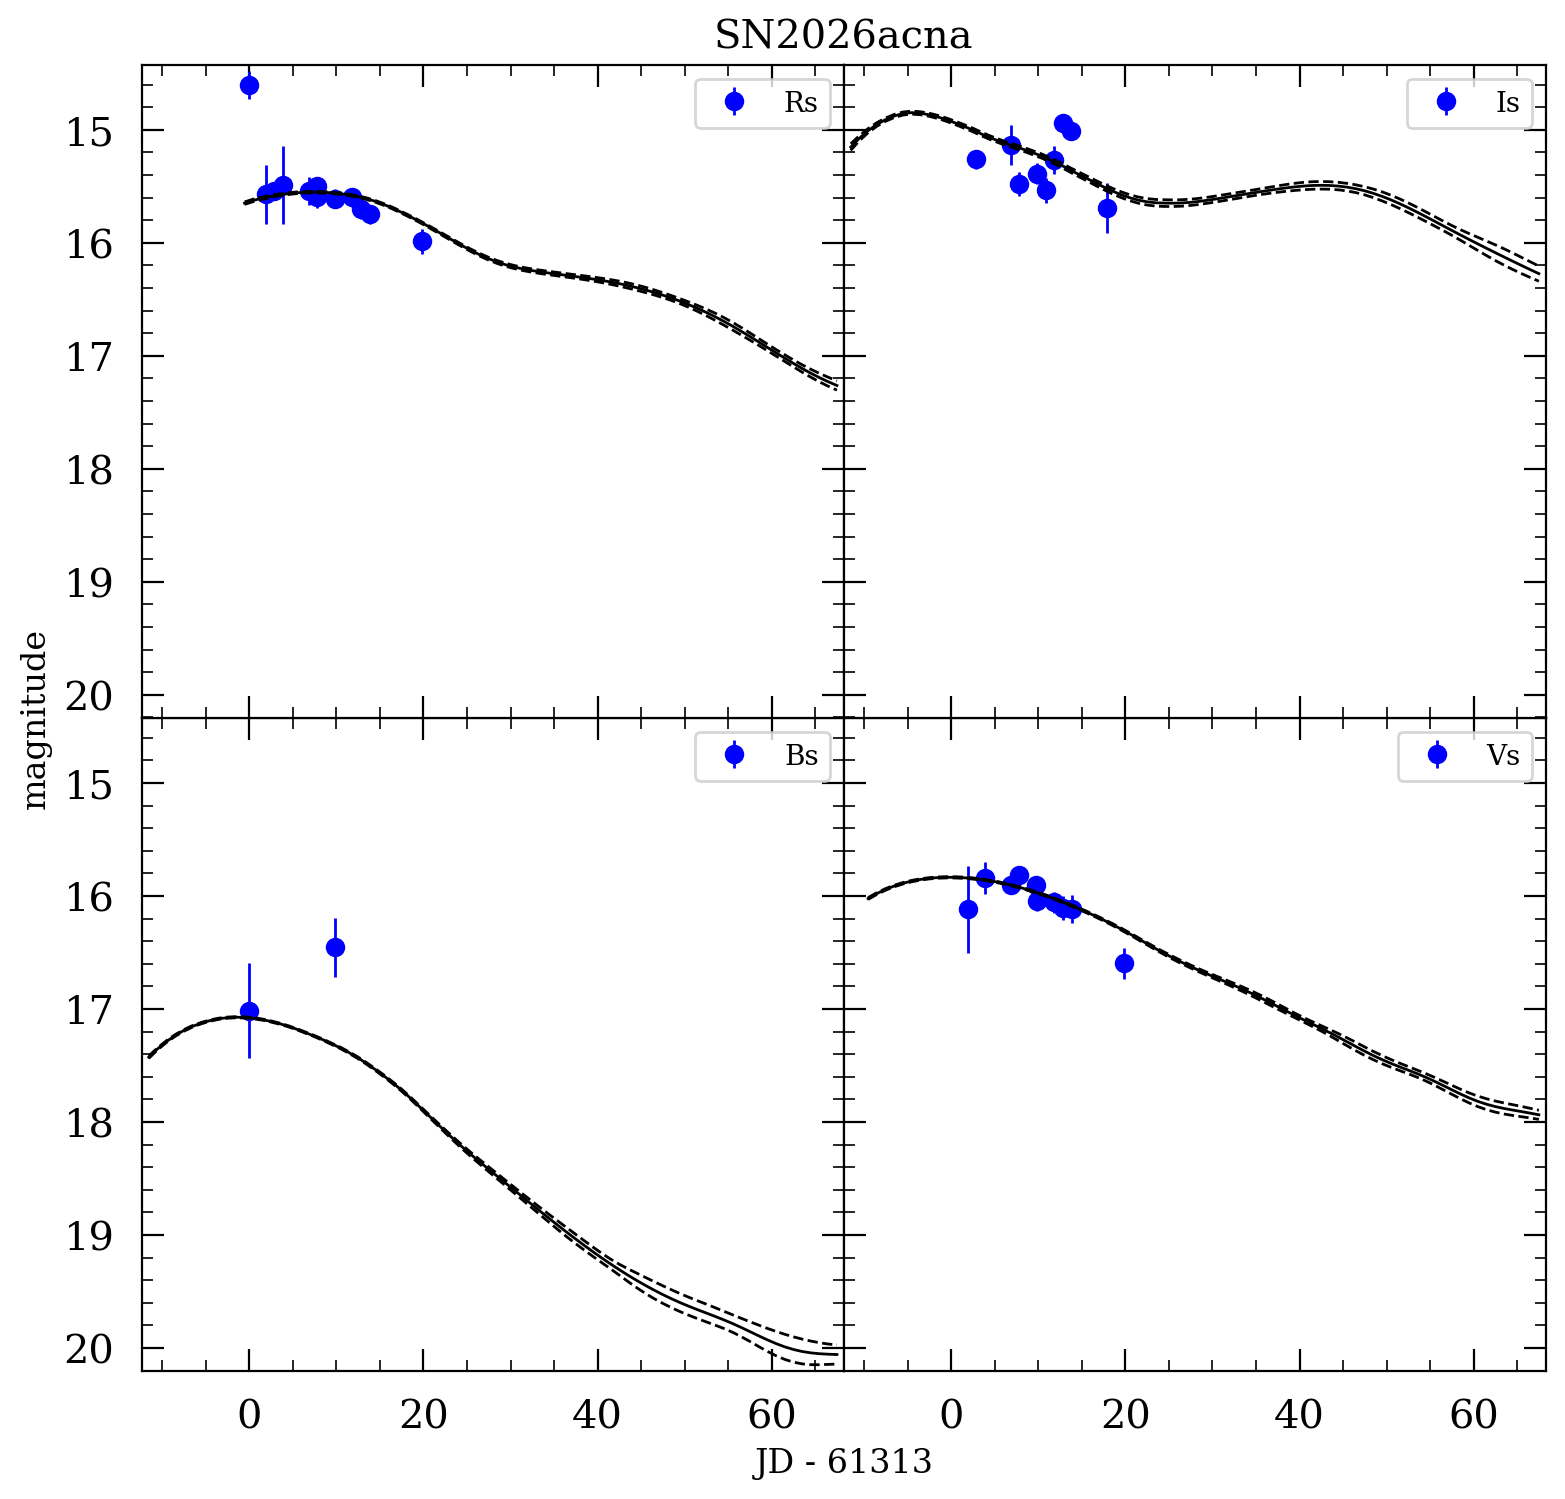

In [31]:
sn_file = output_folder / "SN2026acna_snoopy.txt"
sn_file = output_folder / "SN2026acna.snpy"

s = get_sn(str(sn_file))
s.choose_model("EBV_model2", stype="st")
s.fit()
s.summary()

s.plot(outfile=str(output_folder / f"{s.name}_fit.pdf"))

with (output_folder / f"{s.name}_summary.txt").open("w") as file:
    s.summary(out=file)

s.save(str(output_folder / f"{s.name}.snpy"))

--------------------------------------------------------------------------------
SN  SN2026aeiv
z = 0.0078          zcmb = 0.0076          ra= 49.17428         dec= 80.80253 
Data in the following bands: Bs,  Vs,  Rs,  Is,  
Fit results (if any):
   DM = 32.186  +/-  0.090  +/- 0.221 (sys)
   st = 0.569  +/-  0.096  +/- 0.030 (sys)
   EBVhost = 0.828  +/-  0.150  +/- 0.060 (sys)
   Tmax = 61326.744  +/-  1.008  +/- 0.340 (sys)


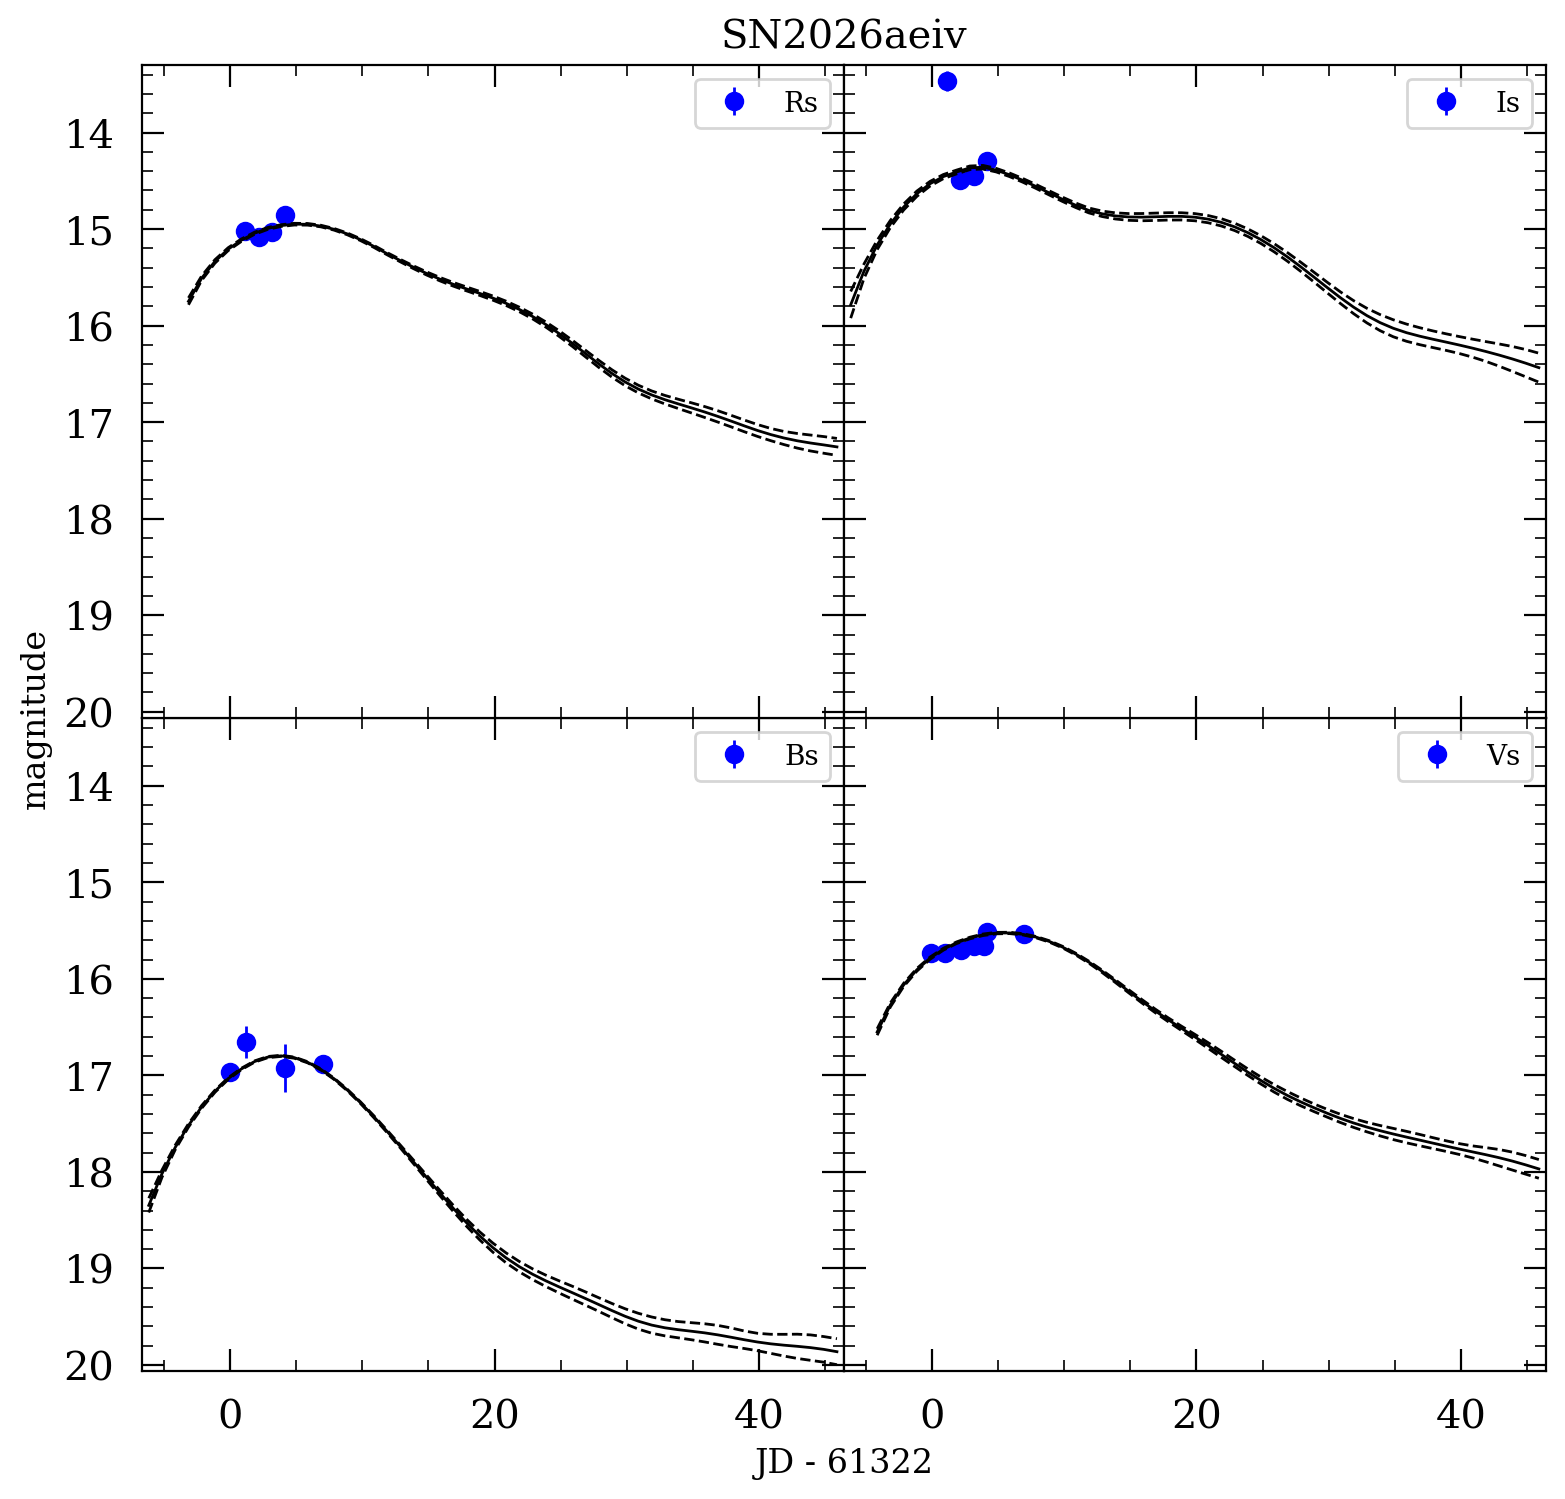

In [32]:
sn_file = output_folder / "SN2026aeiv_snoopy.txt"
sn_file = output_folder / "SN2026aeiv.snpy"

s = get_sn(str(sn_file))
s.choose_model("EBV_model2", stype="st")
s.fit()
s.summary()


s.plot(outfile=str(output_folder / f"{s.name}_fit.pdf"))

with (output_folder / f"{s.name}_summary.txt").open("w") as file:
    s.summary(out=file)
    

s.save(str(output_folder / f"{s.name}.snpy"))